In [26]:
import pandas as pd
import muspan as ms
import os
import numpy as np
import matplotlib.pyplot as plt

In [2]:
muspan_csvs = r"C:\Users\ewestlund\Documents\QuPath\Chanthirika_CAF-panel\Refined_classifications\muspan_output_KNN8_ex139_NEW\NewNeighbourhoodID_output\csvs"
files = [f for f in os.listdir(muspan_csvs) if f.endswith(".csv")]

neighbourhood_summary = r"C:\Users\ewestlund\Documents\QuPath\Chanthirika_CAF-panel\Refined_classifications\muspan_output_KNN8_ex139_NEW\neighbourhood_distribution.csv"

In [3]:
with open(neighbourhood_summary, "a") as f_out:
    f_out.write("Sample, Num Detections, Num 0, Num 1, Num 2, Num 3, Num 4, Num 5, Num 6\n")

    for file in files:
        df = pd.read_csv(os.path.join(muspan_csvs, file))

        data = f"{file[-11:-4]}, {len(df)}"
        for i in range(8):
            data += f", {len(df.loc[df['Neighbourhood_ID_KNN_7'] == i])}"

        data += "\n"
        f_out.write(data)

In [32]:
domain0_path = r"C:\Users\ewestlund\Documents\QuPath\Chanthirika_CAF-panel\Refined_classifications\muspan_output_KNN8_ex139_NEW\NewNeighbourhoodID_output\domains\MP26_38_CR1_Scan1_muspan_1390102.csv.muspan"
domain1_path = r"C:\Users\ewestlund\Documents\QuPath\Chanthirika_CAF-panel\Refined_classifications\muspan_output_KNN8_ex139_NEW\NewNeighbourhoodID_output\domains\MP26_38_CR1_Scan1_muspan_1390103.csv.muspan"

domain2_path = r"C:\Users\ewestlund\Documents\QuPath\Chanthirika_CAF-panel\Refined_classifications\muspan_output_KNN8_ex139_NEW\NewNeighbourhoodID_output\domains\MP26_38_CR1_Scan1_muspan_1390301.csv.muspan"
domain3_path = r"C:\Users\ewestlund\Documents\QuPath\Chanthirika_CAF-panel\Refined_classifications\muspan_output_KNN8_ex139_NEW\NewNeighbourhoodID_output\domains\MP26_38_CR2_Scan1(1)_muspan_1390402.csv.muspan"


domain0 = ms.io.load_domain(domain0_path)
domain1 = ms.io.load_domain(domain1_path)
domain2 = ms.io.load_domain(domain2_path)
domain3 = ms.io.load_domain(domain3_path)

MuSpAn domain loaded successfully. Domain summary:
Domain name: MP26_38_CR1_Scan1_muspan_1390102.csv
Number of objects: 203738
Collections: ['Cell centres']
Labels: ['Phenotype', 'Neighbourhood_ID_KNN_7'] 
Networks: [] 
Distance matrices: []
MuSpAn domain loaded successfully. Domain summary:
Domain name: MP26_38_CR1_Scan1_muspan_1390103.csv
Number of objects: 160594
Collections: ['Cell centres']
Labels: ['Phenotype', 'Neighbourhood_ID_KNN_7'] 
Networks: [] 
Distance matrices: []
MuSpAn domain loaded successfully. Domain summary:
Domain name: MP26_38_CR1_Scan1_muspan_1390301.csv
Number of objects: 117155
Collections: ['Cell centres']
Labels: ['Phenotype', 'Neighbourhood_ID_KNN_7'] 
Networks: [] 
Distance matrices: []
MuSpAn domain loaded successfully. Domain summary:
Domain name: MP26_38_CR2_Scan1(1)_muspan_1390402.csv
Number of objects: 89467
Collections: ['Cell centres']
Labels: ['Phenotype', 'Neighbourhood_ID_KNN_7'] 
Networks: [] 
Distance matrices: []


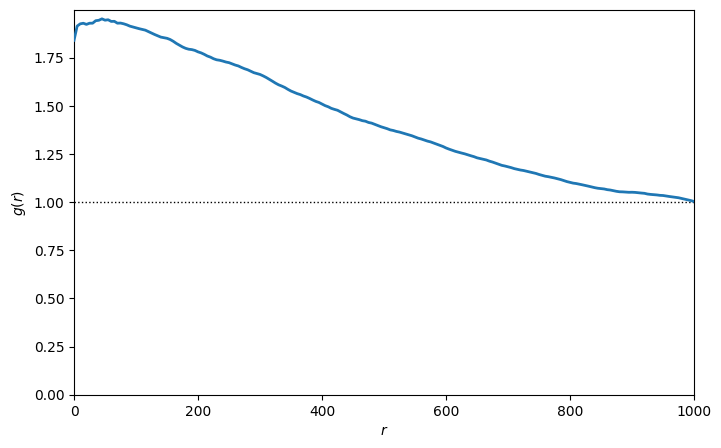

In [20]:
# Query the domain for points of Celltype D
pop_A = ms.query.query(domain0, ('label', 'Phenotype'), 'is', 'CD8')
pop_B = ms.query.query(domain0, ('label', 'Phenotype'), 'is', 'PDGFRa: PDPN: aSMA')

# Calculate the cross-PCF for points of Celltype D with themselves
# max_R: maximum radius to consider
# annulus_step: step size for the annulus
# annulus_width: width of the annulus
# visualise_output: whether to visualise the output
r, PCF = ms.spatial_statistics.cross_pair_correlation_function(
    domain=domain0,
    population_A=pop_A,
    population_B=pop_B,
    max_R=1000,
    annulus_step=5,
    annulus_width=25,
    visualise_output=True
)

(<Figure size 1000x800 with 2 Axes>, <Axes: >)

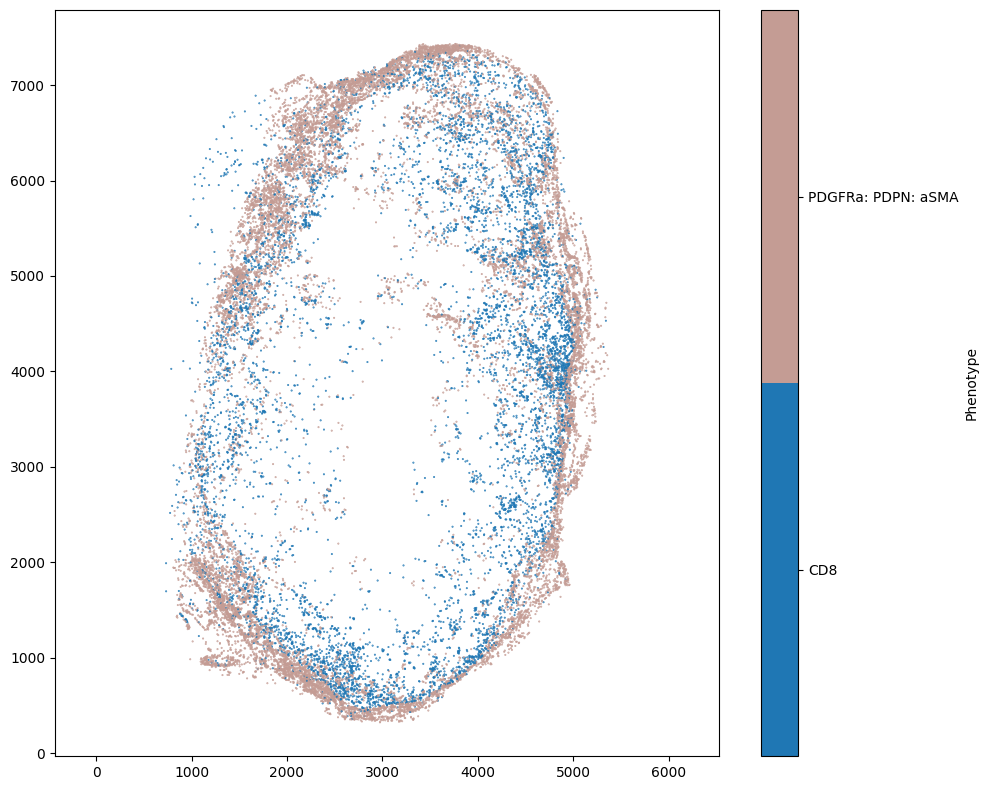

In [12]:
# Combine Query C and Query D using a query container to get all Sox9 transcripts
query_A_and_B = ms.query.query_container(pop_A, 'OR', pop_B)

ms.visualise.visualise(domain0,
                        color_by='Phenotype',
                        show_boundary=False,
                        marker_size=0.2,
                        add_cbar=True,
                        objects_to_plot=query_A_and_B)

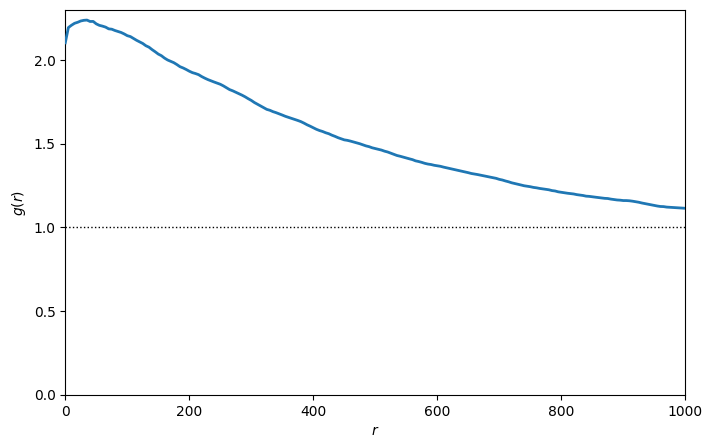

In [21]:
# Query the domain for points of Celltype D
pop_A1 = ms.query.query(domain1, ('label', 'Phenotype'), 'is', 'CD8')
pop_B1 = ms.query.query(domain1, ('label', 'Phenotype'), 'is', 'PDGFRa: PDPN: aSMA')

# Calculate the cross-PCF for points of Celltype D with themselves
# max_R: maximum radius to consider
# annulus_step: step size for the annulus
# annulus_width: width of the annulus
# visualise_output: whether to visualise the output
r, PCF = ms.spatial_statistics.cross_pair_correlation_function(
    domain=domain1,
    population_A=pop_A1,
    population_B=pop_B1,
    max_R=1000,
    annulus_step=5,
    annulus_width=25,
    visualise_output=True
)

(<Figure size 1000x800 with 2 Axes>, <Axes: >)

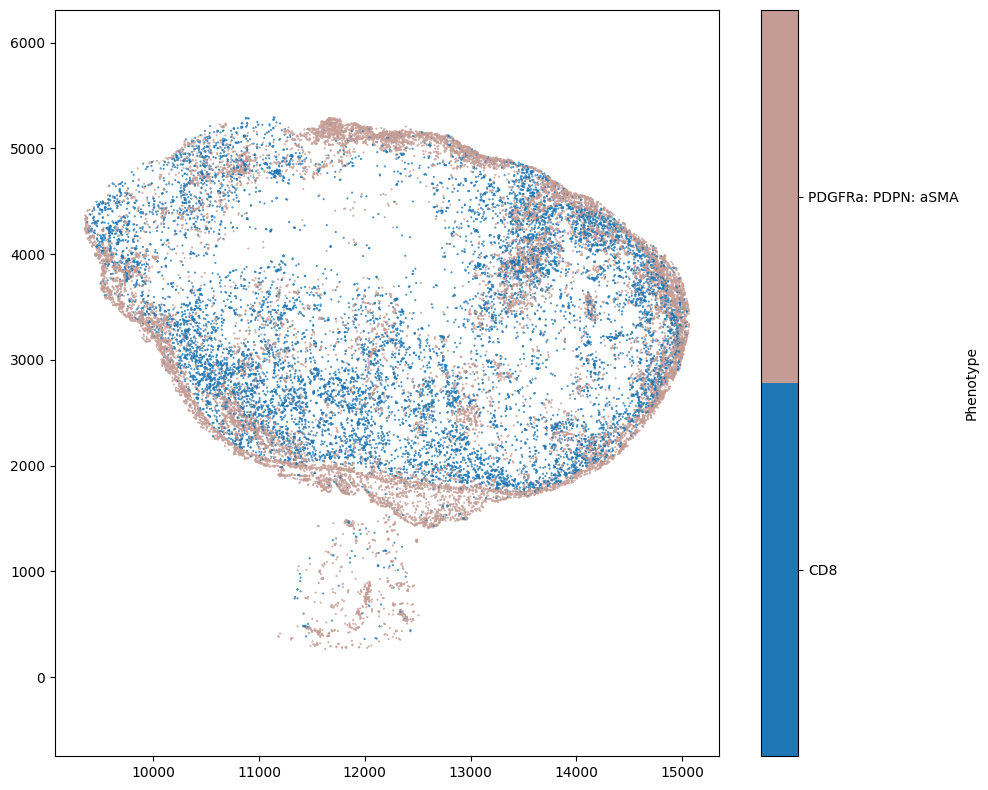

In [16]:
# Combine Query C and Query D using a query container to get all Sox9 transcripts
query_A_and_B1 = ms.query.query_container(pop_A1, 'OR', pop_B1)

ms.visualise.visualise(domain1,
                        color_by='Phenotype',
                        show_boundary=False,
                        marker_size=0.2,
                        add_cbar=True,
                        objects_to_plot=query_A_and_B1)

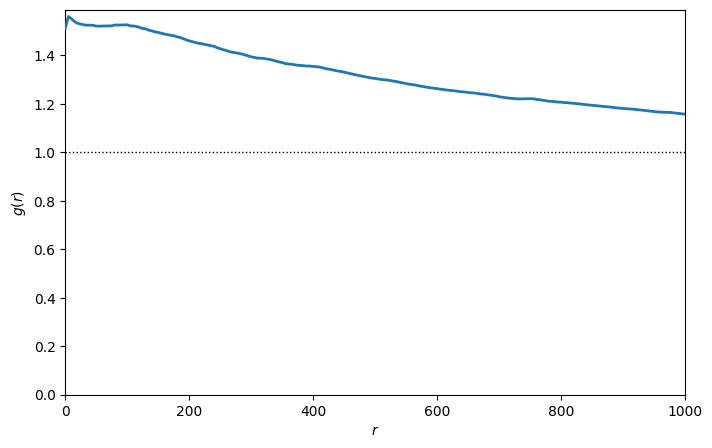

In [23]:
# Query the domain for points of Celltype D
pop_A2 = ms.query.query(domain2, ('label', 'Phenotype'), 'is', 'CD8')
pop_B2 = ms.query.query(domain2, ('label', 'Phenotype'), 'is', 'PDGFRa: PDPN: aSMA')

# Calculate the cross-PCF for points of Celltype D with themselves
# max_R: maximum radius to consider
# annulus_step: step size for the annulus
# annulus_width: width of the annulus
# visualise_output: whether to visualise the output
r, PCF = ms.spatial_statistics.cross_pair_correlation_function(
    domain=domain2,
    population_A=pop_A2,
    population_B=pop_B2,
    max_R=1000,
    annulus_step=5,
    annulus_width=25,
    visualise_output=True
)

(<Figure size 1000x800 with 2 Axes>, <Axes: >)

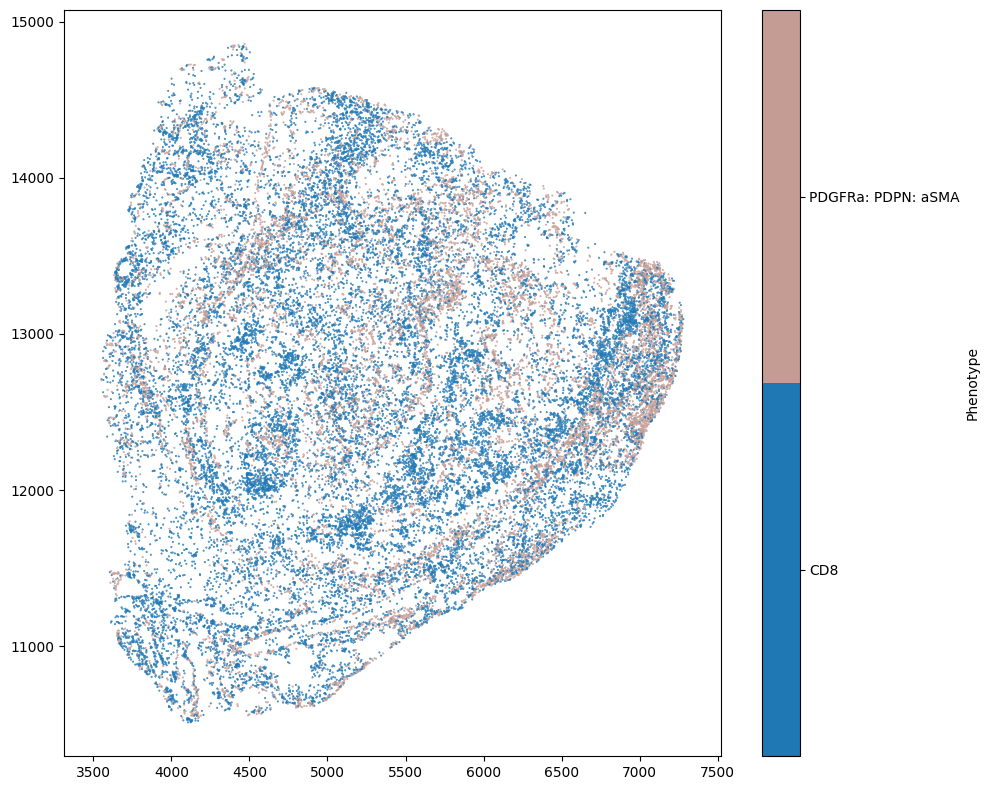

In [24]:
# Combine Query C and Query D using a query container to get all Sox9 transcripts
query_A_and_B2 = ms.query.query_container(pop_A2, 'OR', pop_B2)

ms.visualise.visualise(domain2,
                        color_by='Phenotype',
                        show_boundary=False,
                        marker_size=0.2,
                        add_cbar=True,
                        objects_to_plot=query_A_and_B2)

(<Figure size 1000x800 with 2 Axes>, <Axes: >)

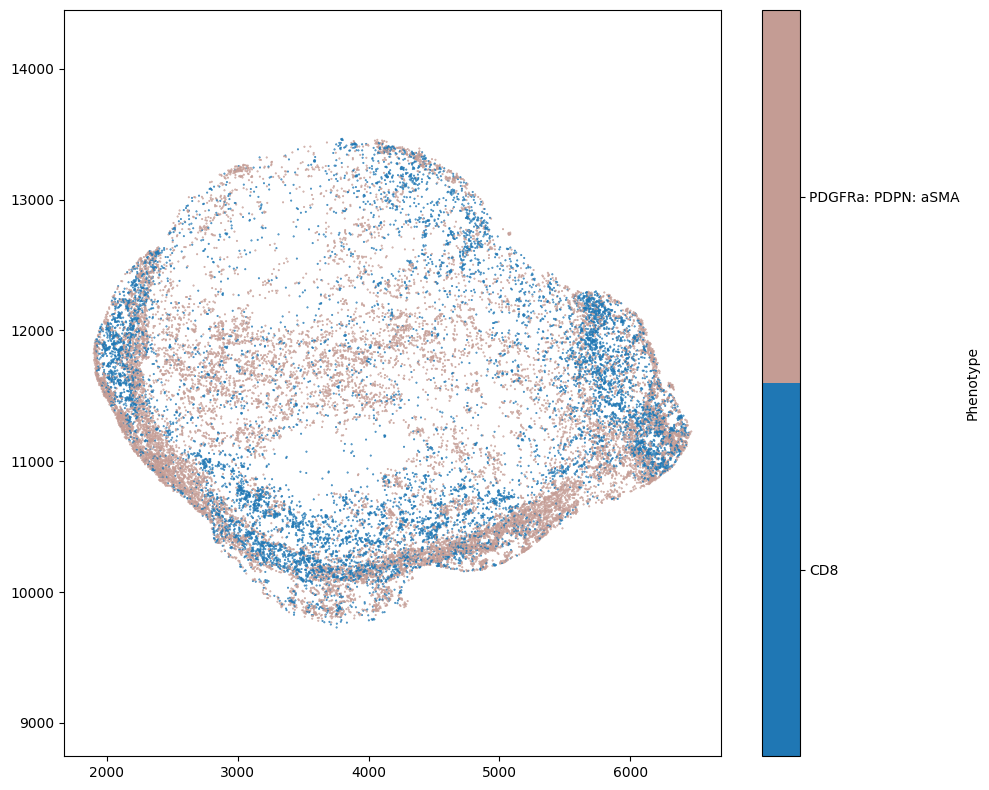

In [39]:
# Query the domain for points of Celltype D
pop_A3 = ms.query.query(domain3, ('label', 'Phenotype'), 'is', 'CD8')
pop_B3 = ms.query.query(domain3, ('label', 'Phenotype'), 'is', 'PDGFRa: PDPN: aSMA')

# Combine Query C and Query D using a query container to get all Sox9 transcripts
query_A_and_B3 = ms.query.query_container(pop_A3, 'OR', pop_B3)

ms.visualise.visualise(domain3,
                        color_by='Phenotype',
                        show_boundary=False,
                        marker_size=0.2,
                        add_cbar=True,
                        objects_to_plot=query_A_and_B3)

In [38]:
r0, PCF0 = ms.spatial_statistics.cross_pair_correlation_function(
    domain=domain0,
    population_A=pop_A,
    population_B=pop_B,
    max_R=2000,
    annulus_step=5,
    annulus_width=25
)

r1, PCF1 = ms.spatial_statistics.cross_pair_correlation_function(
    domain=domain1,
    population_A=pop_A1,
    population_B=pop_B1,
    max_R=2000,
    annulus_step=5,
    annulus_width=25
)

r2, PCF2 = ms.spatial_statistics.cross_pair_correlation_function(
    domain=domain2,
    population_A=pop_A2,
    population_B=pop_B2,
    max_R=2000,
    annulus_step=5,
    annulus_width=25
)

r3, PCF3 = ms.spatial_statistics.cross_pair_correlation_function(
    domain=domain3,
    population_A=pop_A3,
    population_B=pop_B3,
    max_R=2000,
    annulus_step=5,
    annulus_width=25
)

(0.0, 2000.0)

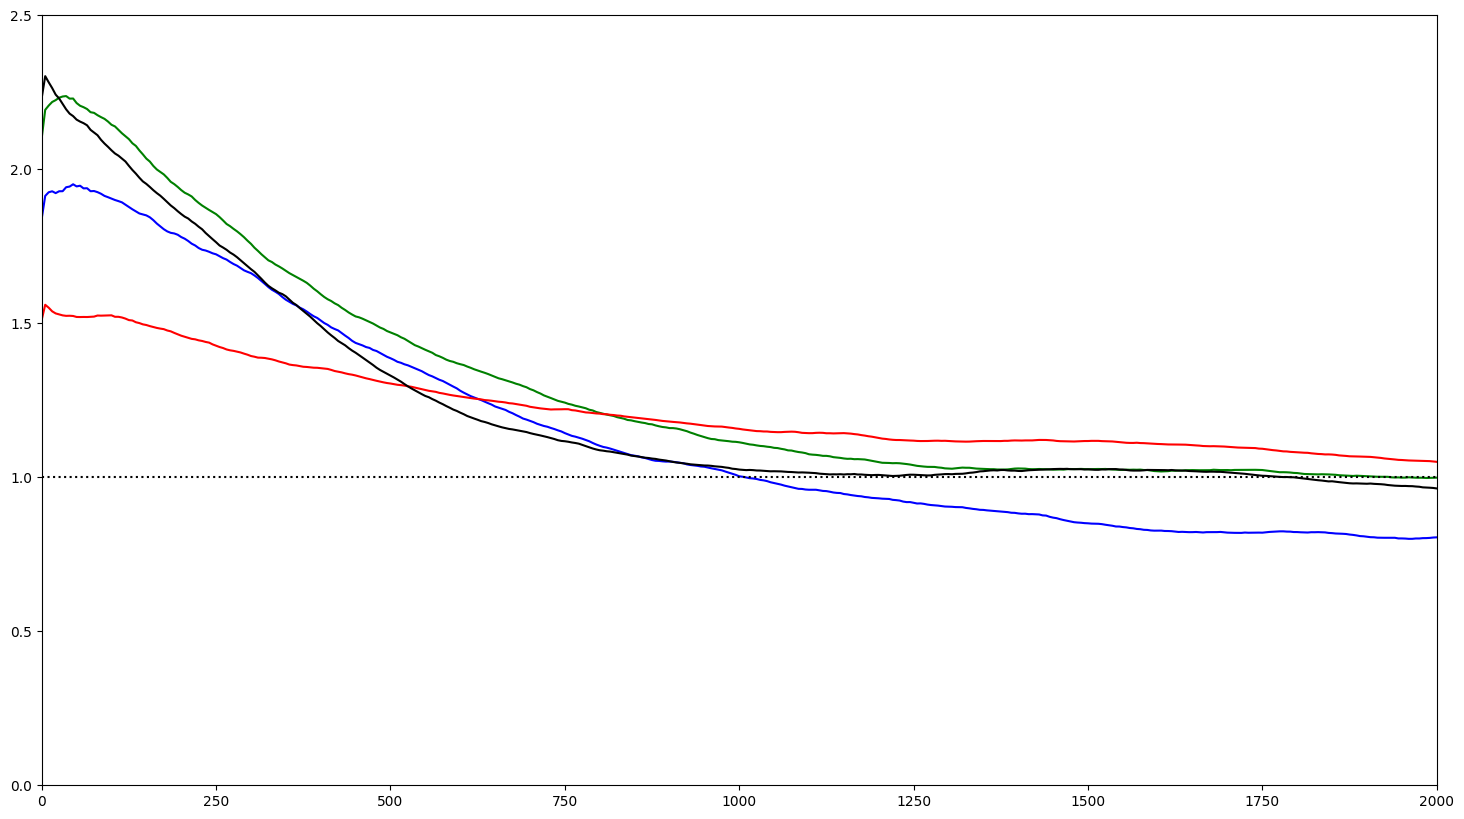

In [40]:
# Create a 4x4 subplot for visualizing the cross-PCF for each combination of cell types
fig, ax = plt.subplots(figsize=(18, 10), ncols=1, nrows=1)

# Plot the cross-PCF
ax.plot(r0, PCF0, 'b')
ax.plot(r1, PCF1, 'g')
ax.plot(r2, PCF2, 'r')
ax.plot(r3, PCF3, 'k')

# Add a horizontal line at y=1 to indicate the CSR baseline
ax.axhline(1, color='k', linestyle=':')

# Set the y-axis limit
ax.set_ylim([0, 2.5])
ax.set_xlim([0, 2000])


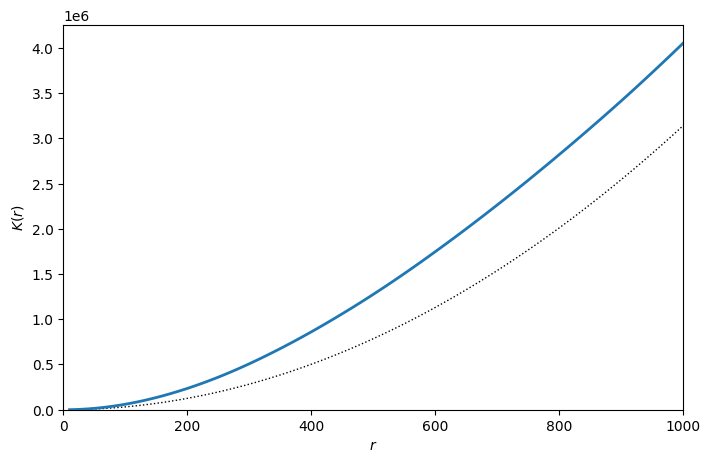

In [43]:
# compute and visualise the standard Ripely's K-function
# by computing the cross K-function where population A = population A
radii,k_values = ms.spatial_statistics.cross_k_function(domain0,
                                                        population_A=pop_A,
                                                        population_B=pop_B,
                                                        step = 10,
                                                        max_R = 1000,
                                                        visualise_output=True)